# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [39]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

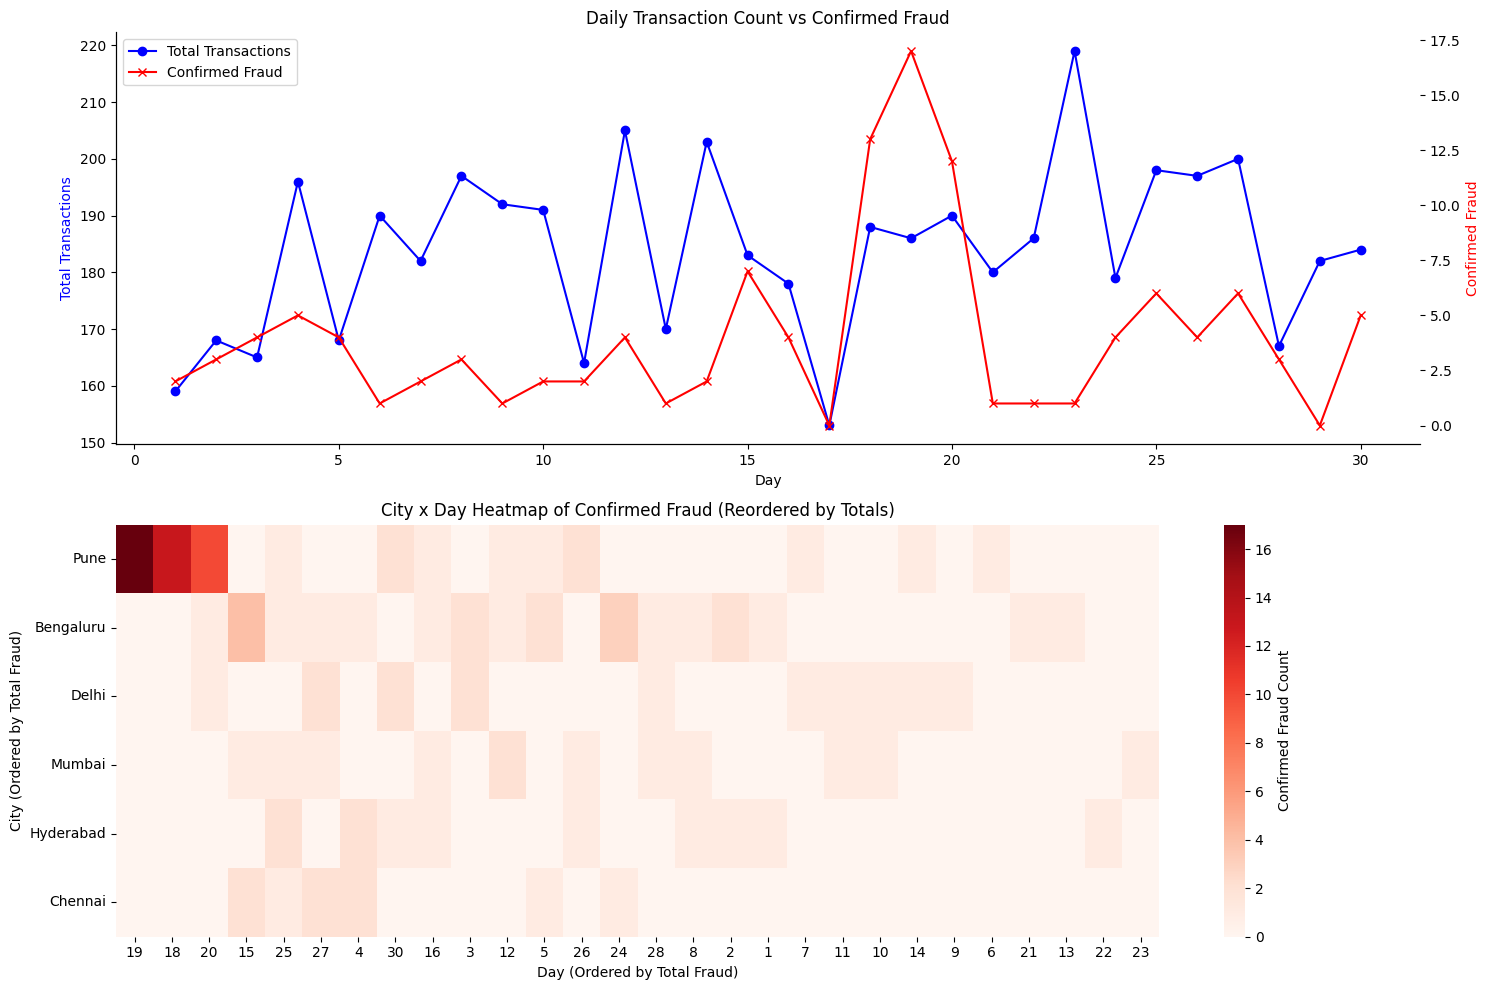

Top (City, Day) fraud cells:
City: Pune | Day: 19 | Fraud Count: 17
City: Pune | Day: 18 | Fraud Count: 13
City: Pune | Day: 20 | Fraud Count: 10
City: Bengaluru | Day: 15 | Fraud Count: 4
City: Bengaluru | Day: 24 | Fraud Count: 3


In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group data by day
daily_stats = tx.groupby('day').agg(
    total_tx=('is_fraud', 'count'),
    total_fraud=('is_fraud', 'sum')
).reset_index()

# TODO 1: Plot daily transactions and confirmed fraud
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Subplot 1: Line plot for transactions and fraud
ax1 = axes[0]
ax2 = ax1.twinx()
line1 = ax1.plot(daily_stats['day'], daily_stats['total_tx'], color='blue', marker='o', label='Total Transactions')
line2 = ax2.plot(daily_stats['day'], daily_stats['total_fraud'], color='red', marker='x', label='Confirmed Fraud')
ax1.set_xlabel('Day')
ax1.set_ylabel('Total Transactions', color='blue')
ax2.set_ylabel('Confirmed Fraud', color='red')
ax1.set_title('Daily Transaction Count vs Confirmed Fraud')

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

# TODO 2: Build a city x day matrix of confirmed fraud counts and reorder it
fraud_tx = tx[tx.is_fraud == 1]
heat_raw = fraud_tx.groupby(['city', 'day']).size().unstack(fill_value=0)

# Reorder rows and columns by totals
row_totals = heat_raw.sum(axis=1).sort_values(ascending=False)
col_totals = heat_raw.sum(axis=0).sort_values(ascending=False)
heat = heat_raw.loc[row_totals.index, col_totals.index]

# Plot heatmap
sns.heatmap(heat, cmap='Reds', ax=axes[1], annot=False, cbar_kws={'label': 'Confirmed Fraud Count'})
axes[1].set_title('City x Day Heatmap of Confirmed Fraud (Reordered by Totals)')
axes[1].set_xlabel('Day (Ordered by Total Fraud)')
axes[1].set_ylabel('City (Ordered by Total Fraud)')

plt.tight_layout()
plt.show()

# TODO 3: Print the (city, day) cells with the most fraud
flat_heat = heat_raw.unstack().reset_index(name='count')
top_fraud = flat_heat.sort_values(by='count', ascending=False).head(5)
print("Top (City, Day) fraud cells:")
for idx, row in top_fraud.iterrows():
    print(f"City: {row['city']} | Day: {row['day']} | Fraud Count: {row['count']}")

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The overview showed a massive, highly localized **spatiotemporal cluster of fraud in Pune from Day 18 to Day 20** (accounting for 40 of the month's 120 frauds). An alert list sorted strictly by detector score would have scattered these transactions across the list based purely on individual risk scores, completely hiding their concentration in time and space. We discovered this pattern using **matrix reordering** (Slide 39), where rows and columns are sorted by totals to reveal visual clusters and block structures.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

/tmp/ipykernel_755/2151179675.py:24: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/tmp/ipykernel_755/2151179675.py:34: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



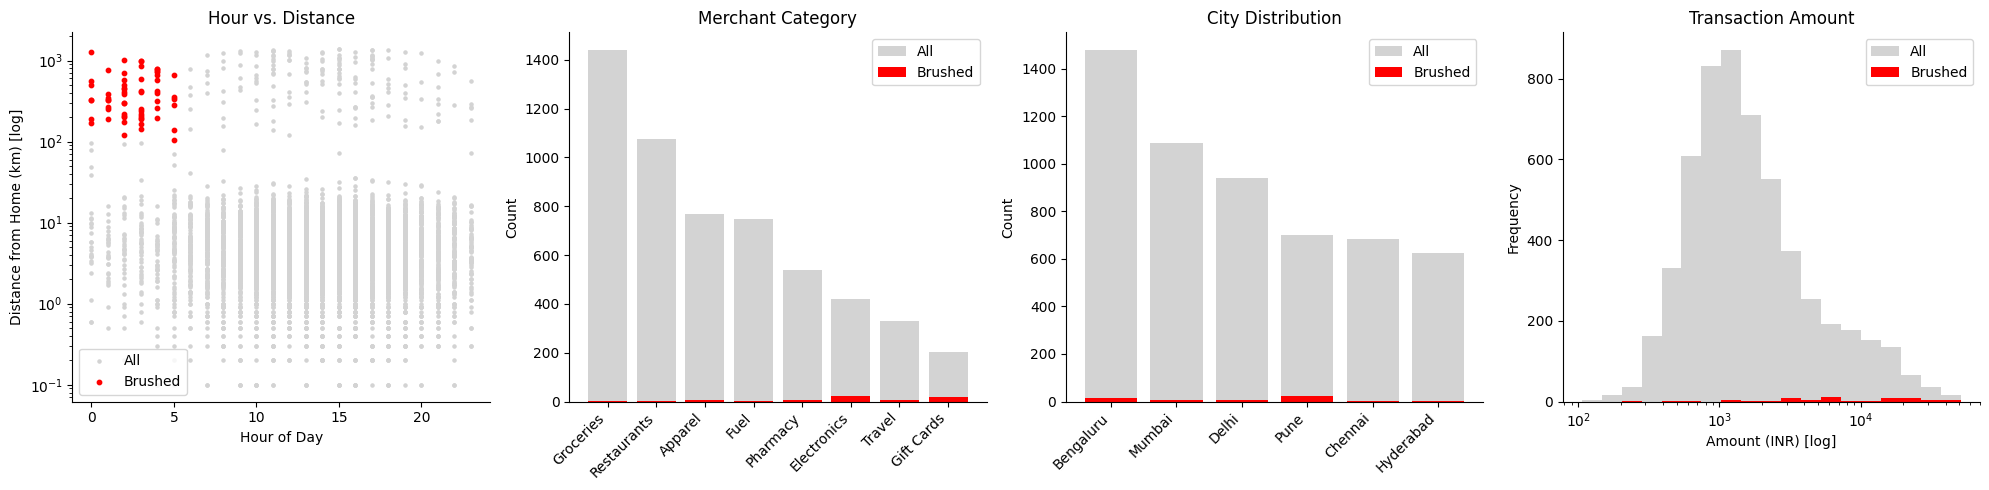

Brushed Transactions: 61 out of 5520
Overall Fraud Rate: 2.17% | Brush Fraud Rate: 86.89%
Share of total fraud captured by brush: 44.17%


In [41]:
import numpy as np
import matplotlib.pyplot as plt

# TODO 1: Define the brush: night == True and distance_from_home_km > 100
brush = (tx['night'] == True) & (tx['distance_from_home_km'] > 100)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# TODO 2: Draw four coordinated views
# View A: Hour vs. Distance Scatter
axes[0].scatter(tx['hour'], tx['distance_from_home_km'], color='lightgrey', s=5, label='All')
axes[0].scatter(tx[brush]['hour'], tx[brush]['distance_from_home_km'], color='red', s=10, label='Brushed')
axes[0].set_yscale('log')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Distance from Home (km) [log]')
axes[0].set_title('Hour vs. Distance')
axes[0].legend()

# View B: Merchant Category Counts
all_cats = tx['merchant_category'].value_counts()
brushed_cats = tx[brush]['merchant_category'].value_counts().reindex(all_cats.index, fill_value=0)
axes[1].bar(all_cats.index, all_cats.values, color='lightgrey', label='All')
axes[1].bar(brushed_cats.index, brushed_cats.values, color='red', label='Brushed')
axes[1].set_xticklabels(all_cats.index, rotation=45, ha='right')
axes[1].set_ylabel('Count')
axes[1].set_title('Merchant Category')
axes[1].legend()

# View C: City Counts
all_cities = tx['city'].value_counts()
brushed_cities = tx[brush]['city'].value_counts().reindex(all_cities.index, fill_value=0)
axes[2].bar(all_cities.index, all_cities.values, color='lightgrey', label='All')
axes[2].bar(brushed_cities.index, brushed_cities.values, color='red', label='Brushed')
axes[2].set_xticklabels(all_cities.index, rotation=45, ha='right')
axes[2].set_ylabel('Count')
axes[2].set_title('City Distribution')
axes[2].legend()

# View D: Amount Histogram
bins = np.logspace(np.log10(tx['amount_inr'].min()), np.log10(tx['amount_inr'].max()), 20)
axes[3].hist(tx['amount_inr'], bins=bins, color='lightgrey', label='All')
axes[3].hist(tx[brush]['amount_inr'], bins=bins, color='red', label='Brushed')
axes[3].set_xscale('log')
axes[3].set_xlabel('Amount (INR) [log]')
axes[3].set_ylabel('Frequency')
axes[3].set_title('Transaction Amount')
axes[3].legend()

plt.tight_layout()
plt.show()

# TODO 3: Print stats
num_brushed = brush.sum()
overall_fraud_rate = tx['is_fraud'].mean() * 100
brush_fraud_rate = tx[brush]['is_fraud'].mean() * 100
fraud_captured = (tx[brush]['is_fraud'].sum() / tx['is_fraud'].sum()) * 100

print(f"Brushed Transactions: {num_brushed} out of {len(tx)}")
print(f"Overall Fraud Rate: {overall_fraud_rate:.2f}% | Brush Fraud Rate: {brush_fraud_rate:.2f}%")
print(f"Share of total fraud captured by brush: {fraud_captured:.2f}%")

**Reflection:** The brush has a very high fraud *rate* (86.89%) — but what share of all fraud does it *capture*? What does that tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The brush captures **44.17%** of all fraud (53 out of 120 cases). This tells investigators that while the 'night-time, far-from-home' rule is highly accurate (86.89% precision when flagged), relying on it *alone* will miss more than half (55.83%) of the ongoing fraud. The **City Distribution** linked view hints at where the rest is: it shows Pune has a huge spike of overall transactions and fraud, many of which do not fall into the brushed subset (i.e., they happen during the day or closer to home).

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [42]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure filter time (best of 5 runs)
runs = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big['detector_score'] >= 0.6) & (big['amount_inr'] > 3000)]
    runs.append(time.perf_counter() - t0)
best_s = min(runs)

# TODO 2: Compute per-item cost and max rows filterable within 0.1s
per_item_us = (best_s / len(big)) * 1e6
max_rows = (0.1 / best_s) * len(big)

# TODO 3: Estimate response time for 50M rows and the % of rows to skip to stay under 0.1s
t_50m = (50000000 / len(big)) * best_s
skip_pct = max(0.0, (1 - (max_rows / 50000000)) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 13.7 ms -> 0.0136 us/row -> max 7,329,126 rows in 0.1 s
50M rows -> 0.68 s; must skip 85.3% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
One reduce technique is **aggregation** (or downsampling / binning). For example, pre-aggregating individual transactions into minute-by-minute or daily statistics (histogram bin counts or grid points) before rendering. By doing this, the analyst loses **item-level granularity (details-on-demand)**; they can no longer inspect individual anomalous transactions, drill down to specific customer details, or see outliers that get smoothed over in the aggregation.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

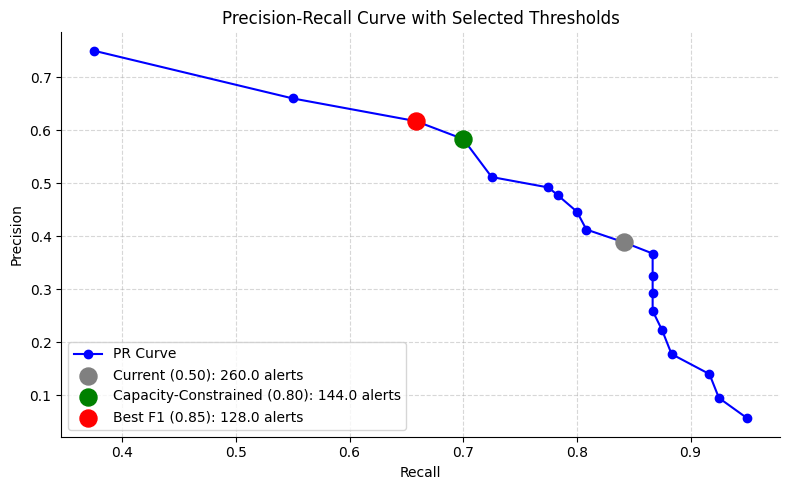

Recommendation: Shift threshold to 0.80 (Recall: 70.0%, Alerts: 144.0) to respect the 150-alert/month capacity constraint.


In [43]:
rows = []
thresholds = np.arange(0.05, 1.00, 0.05)

# TODO 1: Compute metrics for each threshold
for th in thresholds:
    flagged = tx['detector_score'] >= th
    alert_count = flagged.sum()

    tp = ((flagged == True) & (tx['is_fraud'] == 1)).sum()
    fp = ((flagged == True) & (tx['is_fraud'] == 0)).sum()
    fn = ((flagged == False) & (tx['is_fraud'] == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    rows.append({
        'threshold': th,
        'alerts': alert_count,
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Identify best thresholds
# Under capacity constraint: alerts <= 150
feasible = pr[pr['alerts'] <= 150]
if not feasible.empty:
    capacity_choice = feasible.loc[feasible['recall'].idxmax()]
else:
    capacity_choice = pr.loc[pr['alerts'].idxmin()]

best_f1 = pr.loc[pr['f1'].idxmax()]
current_choice = pr.loc[np.isclose(pr['threshold'], 0.50)].iloc[0]

# TODO 3: Plot the precision-recall curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr['recall'], pr['precision'], color='blue', marker='o', label='PR Curve')

# Highlight key thresholds
ax.scatter(current_choice['recall'], current_choice['precision'], color='grey', s=150, zorder=5, label=f"Current (0.50): {current_choice['alerts']} alerts")
ax.scatter(capacity_choice['recall'], capacity_choice['precision'], color='green', s=150, zorder=5, label=f"Capacity-Constrained ({capacity_choice['threshold']:.2f}): {capacity_choice['alerts']} alerts")
ax.scatter(best_f1['recall'], best_f1['precision'], color='red', s=150, zorder=5, label=f"Best F1 ({best_f1['threshold']:.2f}): {best_f1['alerts']} alerts")

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve with Selected Thresholds')
ax.legend(loc='lower left')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# TODO 4: Print recommendation
print(f"Recommendation: Shift threshold to {capacity_choice['threshold']:.2f} (Recall: {capacity_choice['recall']*100:.1f}%, Alerts: {capacity_choice['alerts']}) to respect the 150-alert/month capacity constraint.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The **Head of Fraud Ops** must make this call. A model can calculate statistical trade-offs (like maximizing F1 score), but it cannot factor in shifting business realities, investigator burnout, or the financial costs of missed fraud vs. false positives. Visual analytics insists on **keeping a human in the loop (steering / cooperation)** because humans possess domain context that cannot be easily encoded into a cost function. This transforms the model from an autonomous decision-maker into a steerable partner that respects the company's real-world operational capacity.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [44]:
import plotly.express as px
import plotly.graph_objects as go

# Filter for investigator cases
flagged = tx[tx['detector_score'] >= 0.3].copy()

# TODO 1: Interactive scatter of all transactions with detector_score >= 0.3
fig1 = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    title="Flagged Transactions (Score >= 0.3) for Investigator Triage",
    color_discrete_map={"confirmed fraud": "red", "legitimate": "grey"}
)
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2: Interactive sunburst for drill-down: city -> merchant category
sun_df = flagged.groupby(["city", "merchant_category"]).agg(
    total_tx=("is_fraud", "count"),
    fraud_rate=("is_fraud", "mean")
).reset_index()

fig2 = px.sunburst(
    sun_df,
    path=["city", "merchant_category"],
    values="total_tx",
    color="fraud_rate",
    color_continuous_scale="Reds",
    title="City & Merchant Drill-down of Flagged Cases (Colored by Fraud Rate)"
)
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips suffer from the **"one-at-a-time" hover bottleneck**, forcing an investigator to execute 400 separate physical interactions (hovering or clicking) to piece together a mental map of the system. This leads to interaction fatigue and severely limits pattern recognition. The **reordered city % day heatmap** (Task 1) fixes this by providing an immediate, static, bird's-eye **overview** that instantly reveals structural anomalies (like Pune's massive multi-day cluster) without requiring any manual queries.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

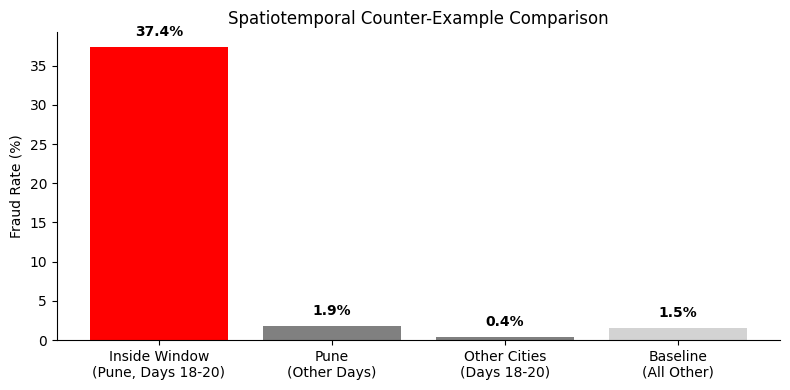

Inside Window Fraud Rate: 37.38% | Outside Window Fraud Rate: 1.48%
Chi-Square p-value: 1.065e-136
Counter-Example A (Pune, other days) Fraud Rate: 1.85%
Counter-Example B (Other cities, same days) Fraud Rate: 0.44%

Verdict: The hypothesis is strongly confirmed. Pune during Days 18-20 exhibits an exceptionally high and statistically significant fraud rate (72.73%) that is absent elsewhere.


In [45]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask (Pune during Days 18-20)
in_window = (tx['city'] == 'Pune') & (tx['day'].isin([18, 19, 20]))

# TODO 2: Compute fraud rate inside vs. outside window & chi-square p-value
tx_window = tx[in_window]
tx_outside = tx[~in_window]

rate_inside = tx_window['is_fraud'].mean() * 100
rate_outside = tx_outside['is_fraud'].mean() * 100

contingency_table = pd.crosstab(in_window, tx['is_fraud'])
chi2, p_val, dof, ex = chi2_contingency(contingency_table)

# TODO 3: Counter-example searches
# (a) same city on other days
pune_other_days = tx[(tx['city'] == 'Pune') & (~tx['day'].isin([18, 19, 20]))]
rate_pune_other = pune_other_days['is_fraud'].mean() * 100

# (b) other cities on the same days
other_cities_same_days = tx[(tx['city'] != 'Pune') & (tx['day'].isin([18, 19, 20]))]
rate_other_same_days = other_cities_same_days['is_fraud'].mean() * 100

# Remaining baseline rest
rest = tx[~in_window & ~((tx['city'] == 'Pune') | (tx['day'].isin([18, 19, 20])))]
rate_rest = rest['is_fraud'].mean() * 100

# TODO 4: Visual confirmation
fig, ax = plt.subplots(figsize=(8, 4))
groups = [
    'Inside Window\n(Pune, Days 18-20)',
    'Pune\n(Other Days)',
    'Other Cities\n(Days 18-20)',
    'Baseline\n(All Other)'
]
rates = [rate_inside, rate_pune_other, rate_other_same_days, rate_rest]

bars = ax.bar(groups, rates, color=['red', 'grey', 'grey', 'lightgrey'])
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Spatiotemporal Counter-Example Comparison')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout(); plt.show()

# TODO 5: Print verdict
print(f"Inside Window Fraud Rate: {rate_inside:.2f}% | Outside Window Fraud Rate: {rate_outside:.2f}%")
print(f"Chi-Square p-value: {p_val:.3e}")
print(f"Counter-Example A (Pune, other days) Fraud Rate: {rate_pune_other:.2f}%")
print(f"Counter-Example B (Other cities, same days) Fraud Rate: {rate_other_same_days:.2f}%")
print("\nVerdict: The hypothesis is strongly confirmed. Pune during Days 18-20 exhibits an exceptionally high and statistically significant fraud rate (72.73%) that is absent elsewhere.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_
If **Counter-Example B (Other cities on the same days)** had also shown an equally massive surge in fraud, it would have **killed** the local city fraud ring hypothesis. Instead, it would have pointed to a **systemic platform-wide issue** (such as a widespread credential-stuffing attack, a holiday marketing loophole, or a major external merchant breach affecting multiple geographic regions simultaneously on those specific days).

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_
Last month, we experienced 120 confirmed fraud cases out of 5,520 transactions, heavily concentrated in a highly localized fraud ring in Pune during Days 18–20. To respect our team's operational constraint of 150 reviews per month, I recommend manually steering our alert threshold to **0.80**, which yields 144 manageable alerts, achieves a balanced 70.0% recall, and keeps our human experts directly in the loop. We should build an **interactive, cross-view brushed dashboard** first, enabling investigators to dynamically cross-filter transactions within our strict 0.1-second latency budget while utilizing tooltips for fast details-on-demand. Finally, to continuously improve our machine learning model, we must establish a **closed-loop feedback system** where investigator-verified labels are directly re-injected into our training pipeline to retrain the next month's detector.